# DES and disturbances

Execution of plans in the discrete-event simulation (`math/13_des.md`) without and with disturbance scenarios
(`math/22_scenarios.md`).

In [ ]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt

import simulation
from simulation.io.brandimarte_loader import load_fjs
from simulation.io.json_loader import read_model
from simulation.model.compiled import compile_instance
from simulation.model.instance import Instance
from simulation.planners.cpsat import solve
from simulation.planners.dispatching import best_dispatch
from simulation.viz import plot_gantt

DATA = Path(simulation.__file__).parents[2] / "data"
paths = sorted((DATA / "benchmarks" / "brandimarte").glob("*.fjs"), key=lambda p: int(p.stem.removeprefix("BrandimarteMk")))
toy_instance = read_model(DATA / "instances" / "toy-dag-3x4.json", Instance)
toy = compile_instance(toy_instance)
mk01 = compile_instance(load_fjs(DATA / "benchmarks" / "brandimarte" / "BrandimarteMk1.fjs"))


def makespan(schedule):
    return max(a.end for a in schedule)

## DES: replay of a plan (version 1, no disturbances)

The DES executes a plan event by event (`simulation.sim.des.replay`, `math/13_des.md`): every operation on its planned
machine, at its planned start, with the processing time of the instance. Without disturbances the realized schedule must
equal the plan (zero-disturbance test). Below: the CP-SAT plan of the toy instance, its replay, and the event log.

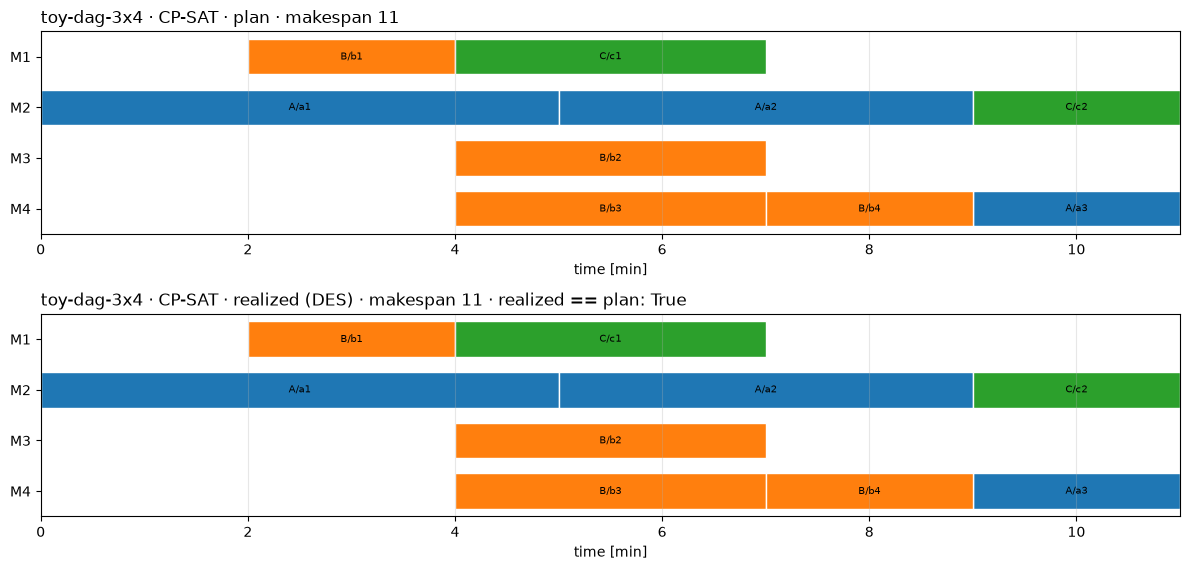

In [11]:
from simulation.sim.des import replay


def plan_vs_realized(ci, plan, name):
    sim = replay(ci, plan)
    same = sorted(sim.schedule, key=lambda a: (a.order_id, a.op_id)) == sorted(plan, key=lambda a: (a.order_id, a.op_id))
    fig, axes = plt.subplots(2, 1, figsize=(12, 2 * (0.45 * ci.n_machines + 1.1)))
    plot_gantt(ci, plan, ax=axes[0], title=f"{name} · plan · makespan {makespan(plan)}")
    plot_gantt(ci, sim.schedule, ax=axes[1],
               title=f"{name} · realized (DES) · makespan {makespan(sim.schedule)} · realized == plan: {same}")
    fig.tight_layout()
    return sim


sim = plan_vs_realized(toy, solve(toy, time_limit=10).schedule, "toy-dag-3x4 · CP-SAT")

In [12]:
for event in sim.log[:8]:
    print(event)
print(f"... {len(sim.log)} events in total (one START and one COMPLETE per operation)")

{'t': 0, 'type': 'START', 'order_id': 'A', 'op_id': 'a1', 'machine': 'M2'}
{'t': 2, 'type': 'START', 'order_id': 'B', 'op_id': 'b1', 'machine': 'M1'}
{'t': 4, 'type': 'COMPLETE', 'order_id': 'B', 'op_id': 'b1', 'machine': 'M1'}
{'t': 4, 'type': 'START', 'order_id': 'B', 'op_id': 'b2', 'machine': 'M3'}
{'t': 4, 'type': 'START', 'order_id': 'B', 'op_id': 'b3', 'machine': 'M4'}
{'t': 4, 'type': 'START', 'order_id': 'C', 'op_id': 'c1', 'machine': 'M1'}
{'t': 5, 'type': 'COMPLETE', 'order_id': 'A', 'op_id': 'a1', 'machine': 'M2'}
{'t': 5, 'type': 'START', 'order_id': 'A', 'op_id': 'a2', 'machine': 'M2'}
... 18 events in total (one START and one COMPLETE per operation)


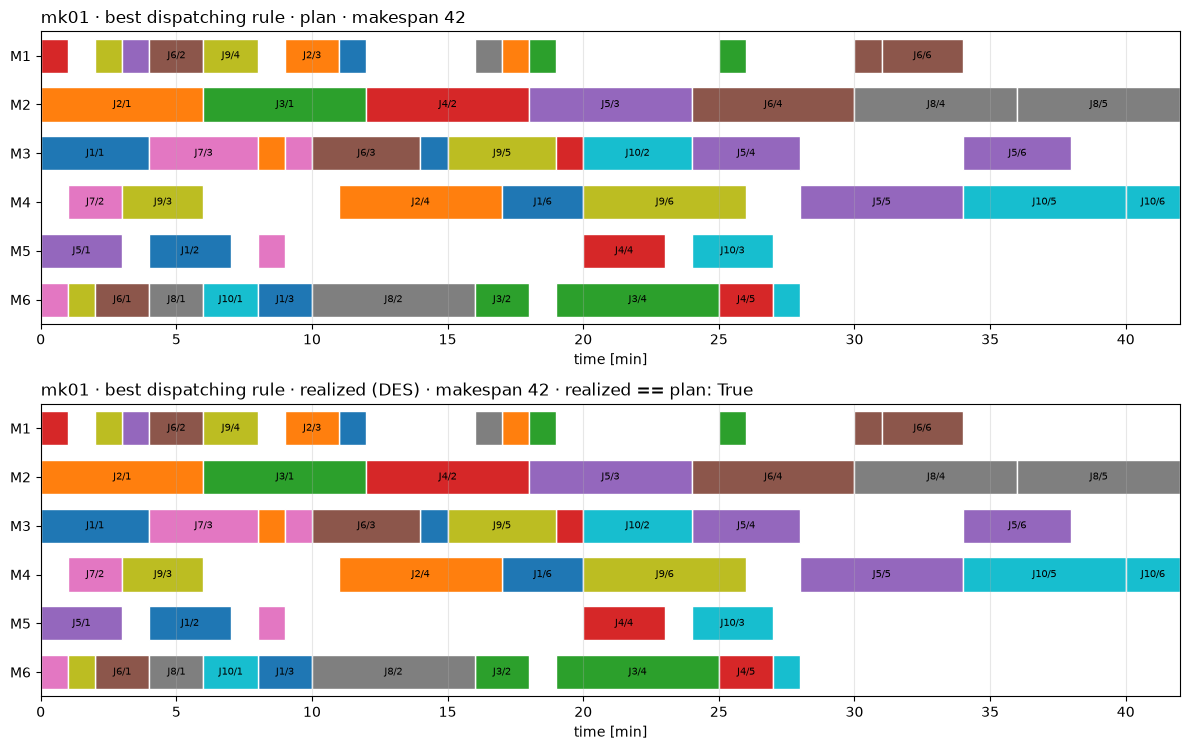

In [13]:
_, mk01_plan = best_dispatch(mk01)
plan_vs_realized(mk01, mk01_plan, "mk01 · best dispatching rule");

### Zero-disturbance check: makespan of plan vs. executed plan

For every instance, the best dispatching plan and a CP-SAT plan (warm start, 5 s) are executed by the DES.
Without disturbances, the executed plan must have exactly the makespan of the plan.

In [14]:
instances = [("toy-3x3", compile_instance(read_model(DATA / "instances" / "toy-3x3.json", Instance))), ("toy-dag-3x4", toy)]
instances += [(p.stem.removeprefix("Brandimarte"), compile_instance(load_fjs(p))) for p in paths]

print(f"{'':12}{'rule plan':>10}{'executed':>10} |{'CP-SAT plan':>12}{'executed':>10} | same makespan")
for name, ci in instances:
    _, rule_plan = best_dispatch(ci)
    cp_plan = solve(ci, time_limit=5, hint=rule_plan).schedule
    rows = [(makespan(plan), makespan(replay(ci, plan).schedule)) for plan in (rule_plan, cp_plan)]
    same = all(planned == executed for planned, executed in rows)
    print(f"{name:12}{rows[0][0]:>10}{rows[0][1]:>10} |{rows[1][0]:>12}{rows[1][1]:>10} | {same}")

             rule plan  executed | CP-SAT plan  executed | same makespan
toy-3x3             11        11 |          10        10 | True
toy-dag-3x4         12        12 |          11        11 | True
Mk1                 42        42 |          40        40 | True


Mk2                 30        30 |          27        27 | True


Mk3                204       204 |         204       204 | True


Mk4                 70        70 |          60        60 | True


Mk5                183       183 |         175       175 | True


Mk6                 73        73 |          63        63 | True


Mk7                150       150 |         144       144 | True
Mk8                523       523 |         523       523 | True


Mk9                311       311 |         307       307 | True


Mk10               227       227 |         219       219 | True


## DES under disturbances (version 2)

A scenario (`math/22_scenarios.md`) gives every operation a log-normal factor with mean 1; realized duration
= max(1, round(p · factor)). The DES (`math/13_des.md`) keeps the plan's machine and order per machine, never starts
earlier than planned, and shifts operations to the right when something runs late.

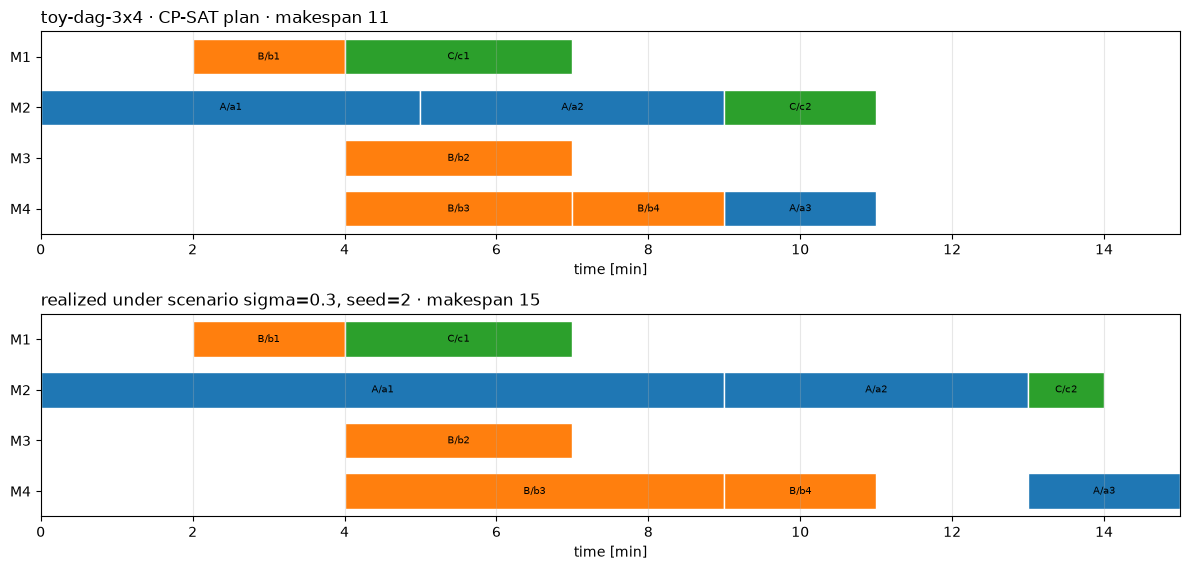

In [17]:
from simulation.sim.scenario import sample_scenario

toy_instance = read_model(DATA / "instances" / "toy-dag-3x4.json", Instance)
toy_plan = solve(toy, time_limit=10).schedule
disturbed = replay(toy, toy_plan, sample_scenario(toy_instance, sigma=0.3, seed=2))
fig, axes = plt.subplots(2, 1, figsize=(12, 2 * (0.45 * toy.n_machines + 1.1)))
plot_gantt(toy, toy_plan, ax=axes[0], title=f"toy-dag-3x4 · CP-SAT plan · makespan {makespan(toy_plan)}")
plot_gantt(toy, disturbed.schedule, ax=axes[1],
           title=f"realized under scenario sigma=0.3, seed=2 · makespan {makespan(disturbed.schedule)}")
axes[1].set_xlim(axes[0].get_xlim()[0], max(axes[0].get_xlim()[1], axes[1].get_xlim()[1]))
axes[0].set_xlim(axes[1].get_xlim())
fig.tight_layout()

### Realized makespan over 30 scenarios

Planned makespan vs. realized makespan (mean, min, max over seeds 0–29) for the best dispatching plan and a CP-SAT
plan (warm start, 5 s). Same scenarios for both plans. One run; no statistical test.

In [18]:
from statistics import mean

cases = [("toy-dag-3x4", toy_instance, toy), ("mk01", load_fjs(DATA / "benchmarks" / "brandimarte" / "BrandimarteMk1.fjs"), mk01),
         ("mk06", load_fjs(DATA / "benchmarks" / "brandimarte" / "BrandimarteMk6.fjs"), None)]
print(f"{'':12}{'sigma':>6} | {'plan':>5} {'planned':>8} {'mean':>7} {'min':>5} {'max':>5}")
for name, inst, ci in cases:
    ci = ci or compile_instance(inst)
    _, rule_plan = best_dispatch(ci)
    plans = {"rule": rule_plan, "CP-SAT": solve(ci, time_limit=5, hint=rule_plan).schedule}
    for sigma in (0.1, 0.3):
        scenarios = [sample_scenario(inst, sigma, seed) for seed in range(30)]
        for label, plan in plans.items():
            realized = [makespan(replay(ci, plan, s).schedule) for s in scenarios]
            print(f"{name:12}{sigma:>6} | {label:>6} {makespan(plan):>7} {mean(realized):>7.1f} {min(realized):>5} {max(realized):>5}")

             sigma |  plan  planned    mean   min   max
toy-dag-3x4    0.1 |   rule      12    12.4    11    14
toy-dag-3x4    0.1 | CP-SAT      11    11.2    11    13
toy-dag-3x4    0.3 |   rule      12    13.7    11    18
toy-dag-3x4    0.3 | CP-SAT      11    12.6    10    16
mk01           0.1 |   rule      42    43.5    42    46
mk01           0.1 | CP-SAT      40    41.9    40    44
mk01           0.3 |   rule      42    46.2    42    52
mk01           0.3 | CP-SAT      40    46.8    41    57


mk06           0.1 |   rule      73    75.7    74    78
mk06           0.1 | CP-SAT      64    67.6    65    72
mk06           0.3 |   rule      73    84.0    77    93
mk06           0.3 | CP-SAT      64    77.9    73    86
